# Chemical and elastic phase separation

I use the website’s dimensionless two-dimensional model, with periodic boundaries, unit mobility and unit gradient coefficient. Composition c is a conserved field. The bulk free-energy density is c²(1-c)². Its derivative contributes 2c(1-c)(1-2c) to chemical potential. The elastic coefficient B(k) is zero for the chemical example. The elastic example uses a homogeneous 2D constitutive model with zero mean stress; it is not a calibrated alloy or a plane-strain reduction of a 3D eigenstrain.

I write one part, test it, then continue. Run the cells in order. This short lesson checks the method; it does not replace the complete simulation or establish convergence.

**Using my code.** I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research (including academic research) and commercial use require my explicit written permission. Earlier MIT and GPL releases retain their existing permissions. Read the [code-use terms](https://saswataiith.github.io/files/CODE-USE-TERMS.txt). Request permission at saswata_at_msme.iith.ac.in. These terms apply to code; teaching text and figures have separate terms.


I choose the mean composition explicitly: `c0 = 0.5`. The small seeded perturbation is added once, at the start. The printed mean checks that the initialization retains this chosen composition. For the chemical free energy $f(c)=c^2(1-c)^2$, its inflection points are $(3-\sqrt{3})/6 \approx 0.2113$ and $(3+\sqrt{3})/6 \approx 0.7887$. Between them, $f^{\prime\prime}(c_0)<0$, so sufficiently long-wavelength composition fluctuations grow. Elasticity adds a further penalty and can narrow this unstable range. Outside the chemical spinodal, small fluctuations decay; nucleation requires a sufficiently large fluctuation or a suitable seed.

Initial random perturbations are different from sustained thermal fluctuations. A thermal Cahn–Hilliard–Cook model uses a conserved random flux, with Gaussian white-noise statistics in the ideal continuum model and amplitude fixed by fluctuation–dissipation. Its discretization depends on cell size and time step. I do not add thermal noise during the evolution here. [Cook’s original paper](https://doi.org/10.1016/0001-6160(70)90144-6).

## Follow the energy, slope and curvature

I begin with the curves, mark the mean composition and then look at the curvature. The last panel joins two nearby compositions in equal amounts. Their mean stays at $c_0$, while their mean chemical energy is $\bar f=[f(c_0-\delta c)+f(c_0+\delta c)]/2$. Here $c_0=0.5$ and $\delta c=0.04$.

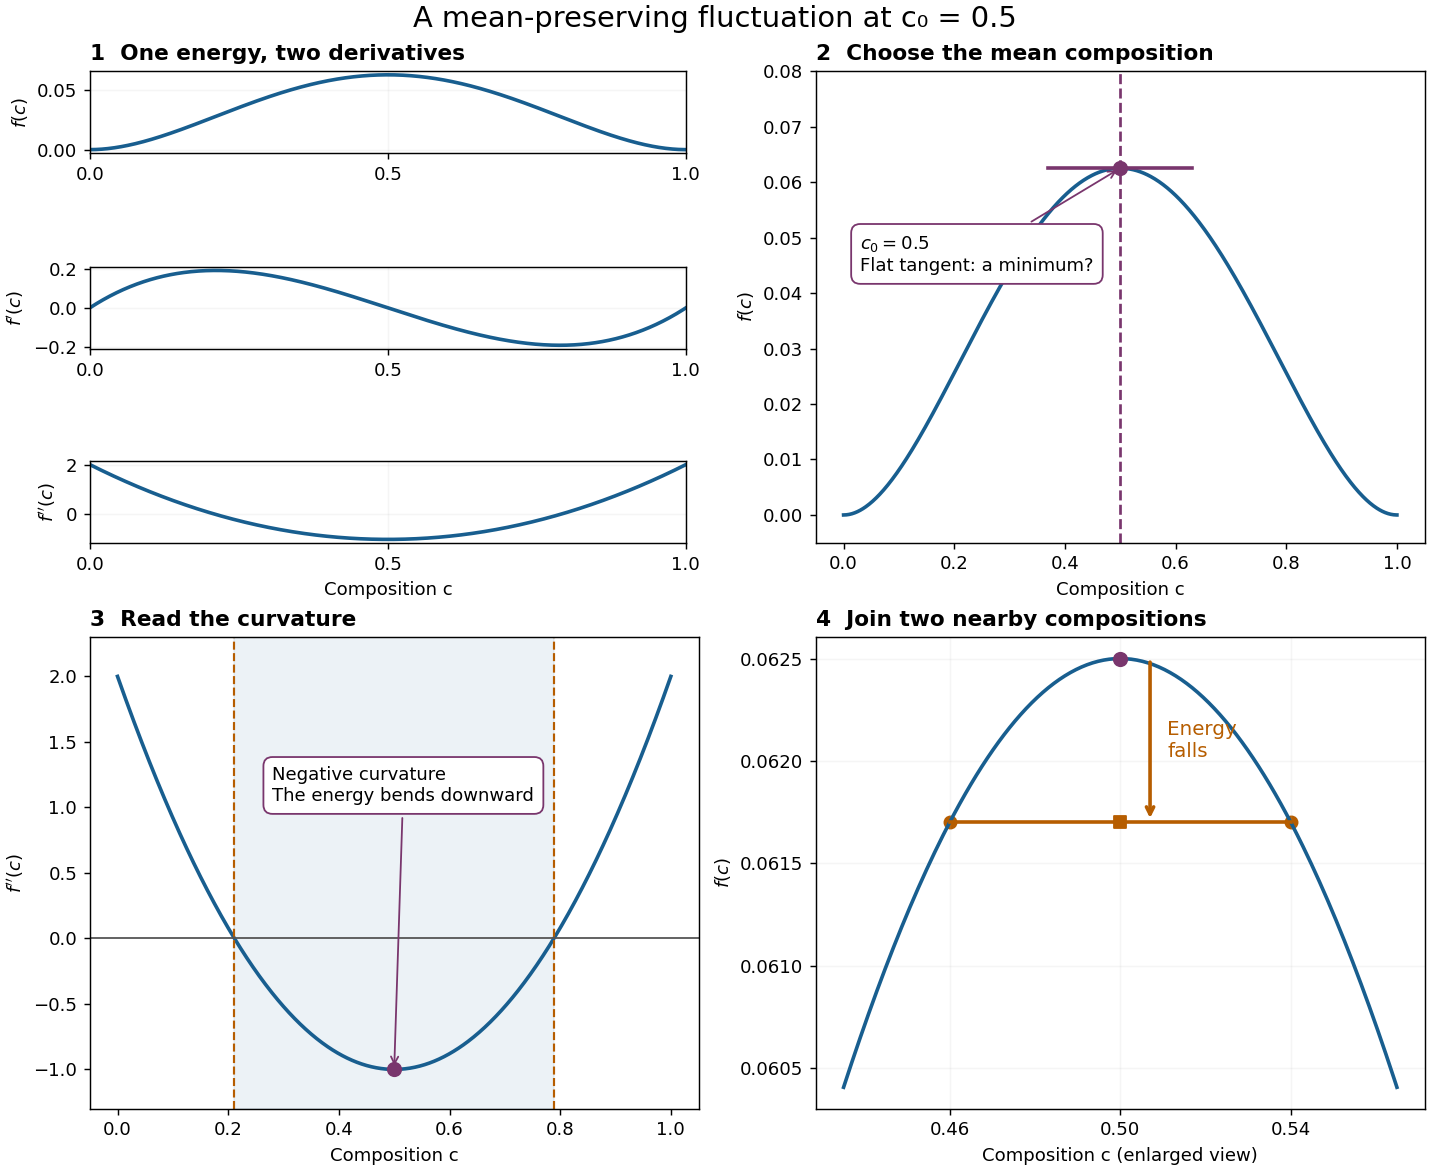

The orange square is the average energy of the two compositions; the purple point is the uniform composition. The downward arrow shows the chemical energy decrease. The connecting line is not the equilibrium common tangent. I compare the bulk chemical term here, before interfacial and elastic costs. The [interactive lesson](https://saswataiith.github.io/resources/step-by-step/phase-field/#mean-composition) lets me repeat this comparison at other compositions.

## Lengthen the chords and follow the energy

I start with a tiny chord and lengthen it toward the common tangent. For the mean $c_0=0.5$, the two amounts remain equal. Their average chemical energy falls throughout this path, until the chord touches the minima at $c=0$ and $c=1$.

At another mean, I use the lever rule to keep that mean fixed. A convenient schematic path is $c_\alpha=(1-s)c_0$, $c_\beta=c_0+s(1-c_0)$, with amounts $v_\alpha=1-c_0$ and $v_\beta=c_0$. Then $v_\alpha c_\alpha+v_\beta c_\beta=c_0$ and $\bar f=v_\alpha f(c_\alpha)+v_\beta f(c_\beta)$.

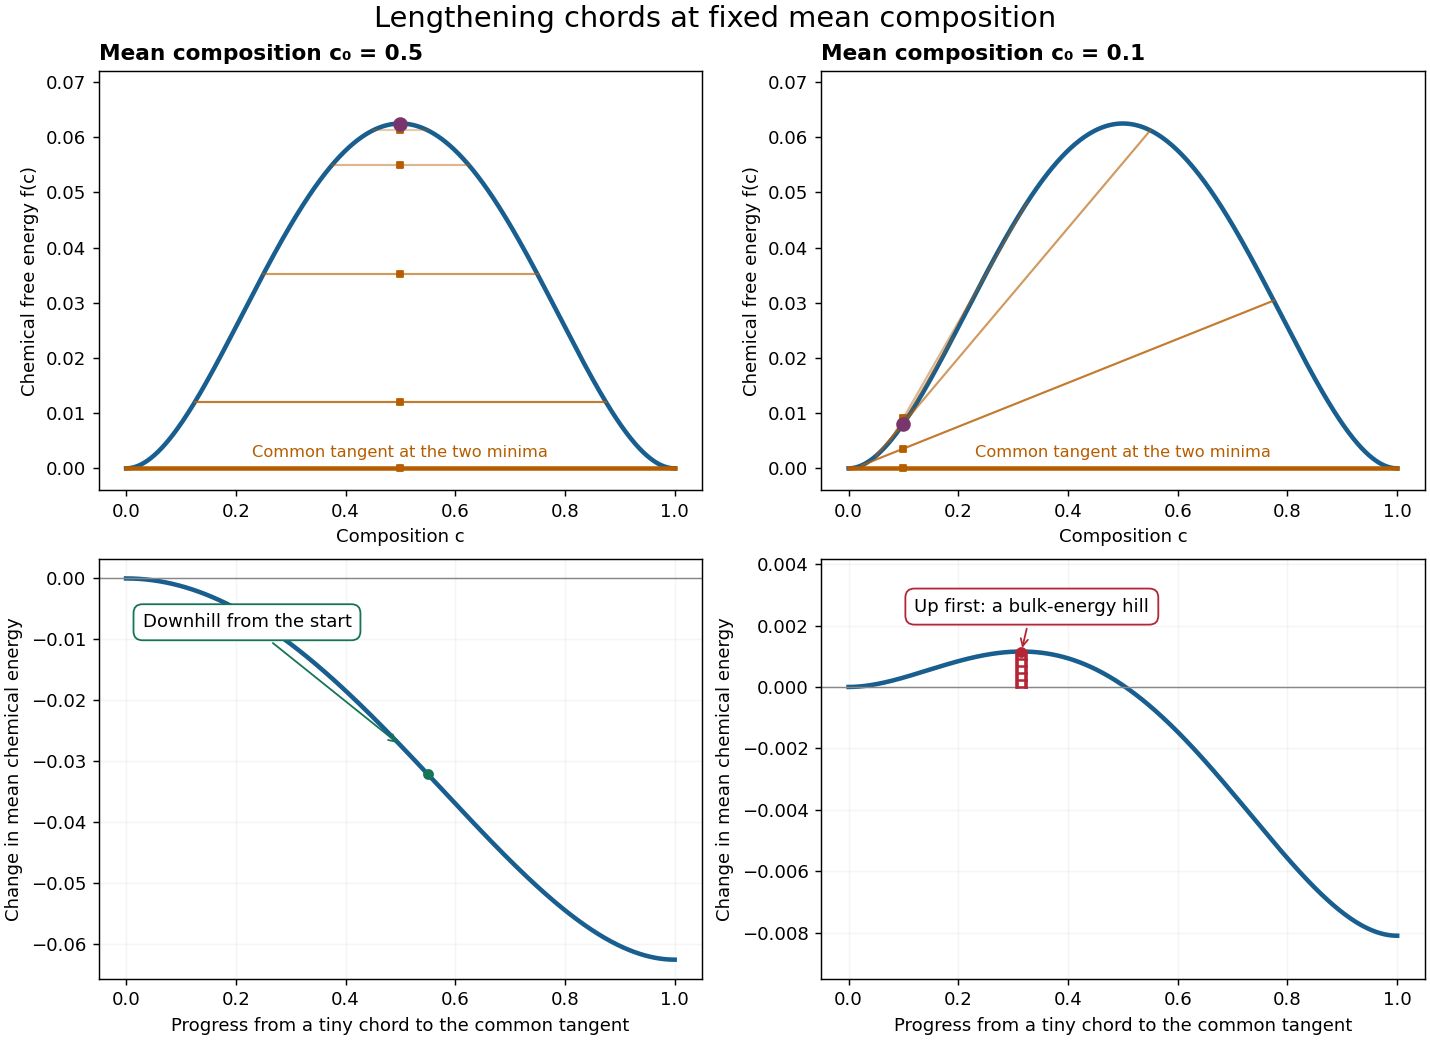

The red ladder shows the bulk-energy rise along this chosen composition path. It is a schematic of the initial uphill step outside the spinodal. A physical nucleation barrier also includes interfacial energy and depends on nucleus geometry.

### The small-fluctuation calculation

For two equal amounts at $c_0-a$ and $c_0+a$, the odd terms in a Taylor expansion cancel. For this quartic potential, the exact chemical-energy change is

$$\Delta\bar f=\frac{f(c_0-a)+f(c_0+a)}{2}-f(c_0)=\frac12 f''(c_0)a^2+a^4.$$

Positive curvature makes these fluctuations costly. Negative curvature makes sufficiently small ones favorable. The chemical spinodal is approximately $0.2113<c_0<0.7887$. For a spatial fluctuation I also include the interfacial and elastic terms. The linear growth rate is

$$\omega(\mathbf k)=-M k^2\left[f''(c_0)+\kappa k^2+B(\mathbf n)\right],\qquad k=|\mathbf k|,\quad\mathbf n=\mathbf k/k.$$

The mode grows when $\omega>0$. In the chemical case, sufficiently long waves can grow inside the spinodal, while the gradient term suppresses very short waves. The conserved zero mode does not grow.


## Step 1: Create wave numbers and the initial field

I start with the chemical case. The grid spacing is one dimensionless length unit. I remove the mean of the seeded random perturbation so that the initial mean composition is exactly 0.5 to floating-point accuracy.

I use NumPy’s random generator with seed 714. Reusing the seed reproduces the initial field in this environment. I subtract the perturbation’s mean to retain mean composition 0.5.

In [1]:
import numpy as np
n = 64
dt = 0.2
k = 2 * np.pi * np.fft.fftfreq(n)
kx, ky = np.meshgrid(k, k, indexing="ij")
k2 = kx**2 + ky**2
c0 = 0.5
seed = 714
rng = np.random.default_rng(seed)
noise = 0.02 * (rng.random((n, n)) - 0.5)
noise -= noise.mean()
initial = c0 + noise
assert abs(initial.mean() - c0) < 1e-12
assert k2[0, 0] == 0
print("Mean composition =", initial.mean())

Mean composition = 0.5


## Step 2: One update and my conservation check

The gradient and elastic terms are implicit; the nonlinear bulk derivative is explicit. The zero Fourier mode is unchanged because k² is zero there. I check the mean and finite values after one update. These checks do not prove energy stability.

In [2]:
chemical_kernel = np.zeros_like(k2)
bulk_derivative = 2 * initial * (1 - initial) * (1 - 2 * initial)
numerator = np.fft.fft2(initial) - dt * k2 * np.fft.fft2(bulk_derivative)
denominator = 1 + dt * k2 * (k2 + chemical_kernel)
one_step = np.fft.ifft2(numerator / denominator).real
assert np.isfinite(one_step).all()
assert abs(one_step.mean() - initial.mean()) < 1e-12
print("Mean change after one update:", one_step.mean() - initial.mean())

Mean change after one update: 0.0


## Step 3: Add the elastic kernel separately

I use the homogeneous elastic-energy kernel [derived here from mechanical equilibrium](https://saswataiith.github.io/research/formulation/appendices/#appendix-a). \(C_{11}\), \(C_{12}\) and \(C_{44}\) are dimensionless elastic stiffnesses here. The dilatational eigenstrain is dimensionless. I check the isotropic limit, in which the nonzero-mode kernel has no angular dependence. I also check that zero misfit removes the elastic contribution.

A real composition field has Fourier coefficients at opposite wave vectors. For each wave vector \(\mathbf{k}\), the coefficient at \(-\mathbf{k}\) is its complex conjugate: the real parts are equal and the imaginary parts have opposite signs,
\[\widehat c(-\mathbf{k})=\widehat c(\mathbf{k})^*.\]
Here the star means complex conjugation. This conjugate symmetry is what allows the inverse Fourier transform to recover a real field.

The elastic kernel in this calculation is real. To preserve that conjugate symmetry during an update, it must have the same value at opposite wave vectors: \(B(-\mathbf{k})=B(\mathbf{k})\). This symmetry already holds analytically for the dilatational kernel used here. I make it explicit in the stored numerical array by replacing the coefficients at opposite wave vectors with their average.

For eight grid points, the picture separates the wave number from its position in the NumPy array. The arrows connect opposite wave numbers; $L$ is the periodic domain length. The dashed $+4$ repeats the $-4$ grid mode, not an extra array entry.

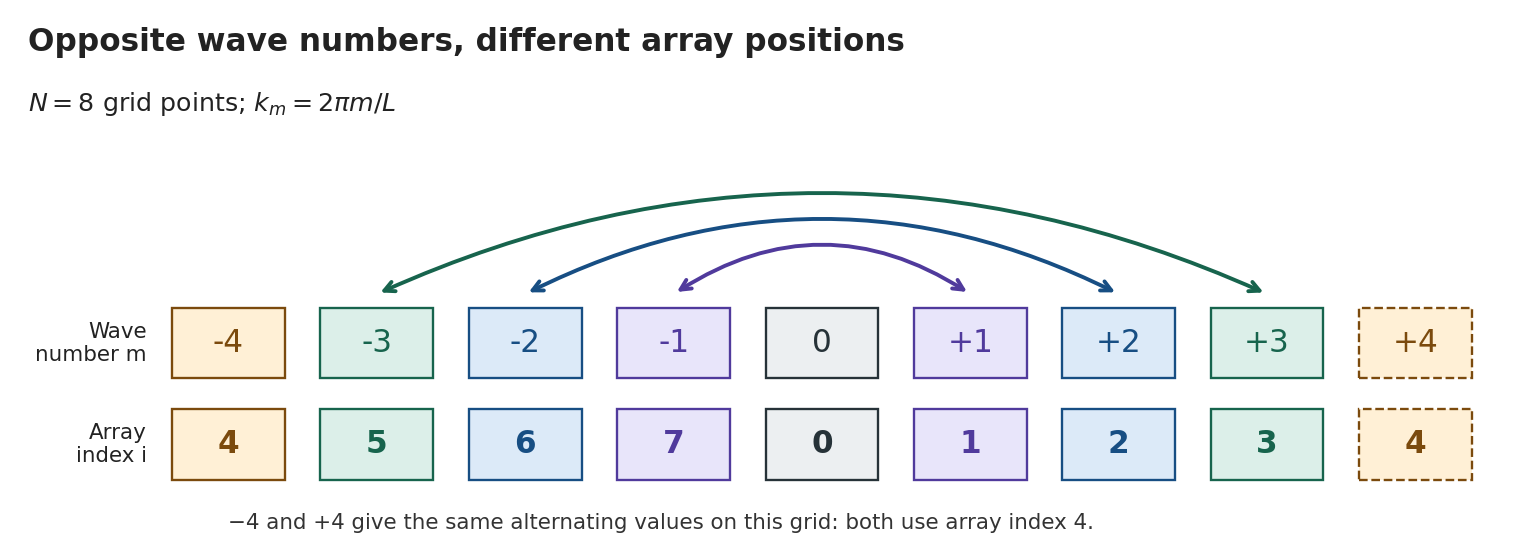

For example, $m=1$ and $m=-1$ are stored at indices 1 and 7. The modulo operation finds this opposite index. In two dimensions I apply the same rule to both directions, so index (1, 2) maps to (7, 6). I average the two kernel values so they agree.

In [3]:
def kernel(kx, ky, c11=4.0, c12=2.0, c44=3.0, eigenstrain=0.2):
    """B = E:C:E - (sigma0.n).Q^-1.(sigma0.n), E=eigenstrain*I.
    Q_ik=C_ijkl*n_j*n_l; Q11=C11*nx²+C44*ny² (not C12).
    This is a 2D constitutive model, not a reduction with epsilon_zz eigenstrain.
    """
    k2 = kx * kx + ky * ky
    radius = np.sqrt(np.where(k2 == 0, 1.0, k2))
    nx, ny = (kx / radius, ky / radius)
    q11 = c11 * nx * nx + c44 * ny * ny
    q22 = c44 * nx * nx + c11 * ny * ny
    q12 = (c12 + c44) * nx * ny
    det = q11 * q22 - q12 * q12
    det = np.where(k2 == 0, 1.0, det)
    stress = (c11 + c12) * eigenstrain
    b = 2 * (c11 + c12) * eigenstrain ** 2 - stress ** 2 * (q22 * nx * nx - 2 * q12 * nx * ny + q11 * ny * ny) / det
    return np.where(k2 == 0, 0.0, b)

angles = np.linspace(0, 2 * np.pi, 33)
isotropic = kernel(np.cos(angles), np.sin(angles), c11=4, c12=2, c44=1)
assert np.ptp(isotropic) < 1e-12
assert np.allclose(kernel(kx, ky, eigenstrain=0), 0)
elastic_kernel = kernel(kx, ky, c11=4, c12=2, c44=3, eigenstrain=0.2)
# Find the opposite Fourier index in each direction.
opposite_index = (-np.arange(n)) % n
# Give opposite wave vectors the same real kernel value.
elastic_kernel = 0.5 * (elastic_kernel + elastic_kernel[np.ix_(opposite_index, opposite_index)])
assert np.isfinite(elastic_kernel).all()
print("Isotropic angular variation:", np.ptp(isotropic))

Isotropic angular variation: 3.3306690738754696e-16


## Step 4: Compare short evolutions with the same initial field

I advance both cases from identical fields for 50 steps. This is a short execution and conservation check. The complete program supplies longer runs and free-energy records. Timestep and spatial refinement are separate questions and have not been established by this notebook.

Final time: 10.0
Field RMS difference: 0.005768896080992374


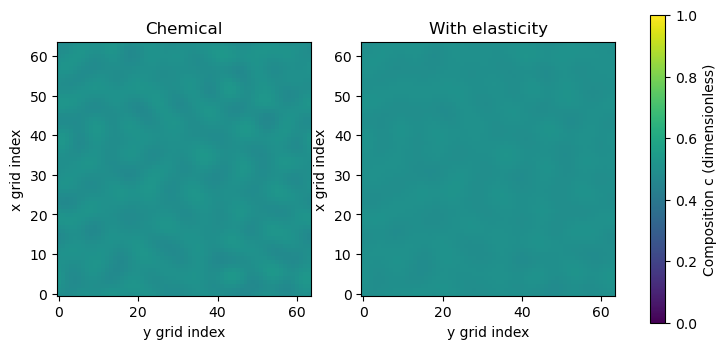

In [4]:
chemical = initial.copy()
elastic = initial.copy()
for step in range(50):
    chemical_bulk = 2 * chemical * (1 - chemical) * (1 - 2 * chemical)
    chemical_spectrum = np.fft.fft2(chemical) - dt * k2 * np.fft.fft2(chemical_bulk)
    chemical = np.fft.ifft2(chemical_spectrum / (1 + dt*k2*(k2 + chemical_kernel))).real
    elastic_bulk = 2 * elastic * (1 - elastic) * (1 - 2 * elastic)
    elastic_spectrum = np.fft.fft2(elastic) - dt * k2 * np.fft.fft2(elastic_bulk)
    elastic = np.fft.ifft2(elastic_spectrum / (1 + dt*k2*(k2 + elastic_kernel))).real
for result in (chemical, elastic):
    assert np.isfinite(result).all()
    assert abs(result.mean() - initial.mean()) < 1e-10
assert np.linalg.norm(chemical - elastic) > 0
print("Final time:", 50 * dt)
print("Field RMS difference:", np.sqrt(np.mean((chemical - elastic)**2)))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, field, name in zip(axes, [chemical, elastic], ["Chemical", "With elasticity"]):
    image = ax.imshow(field, vmin=0, vmax=1, origin="lower")
    ax.set_title(name)
    ax.set_xlabel("y grid index")
    ax.set_ylabel("x grid index")
fig.colorbar(image, ax=axes, label="Composition c (dimensionless)")
plt.show()

## Step 5: Run longer and save the fields

I now use a 256 × 256 grid and run to time 400. The spacing stays at one, so this is a larger periodic domain. I keep the same mean composition, seed 714, time step and energy model. Every 25 updates I save the time and copies of both fields. The copies matter: each saved frame must retain its own values while the calculation continues. The calculation runs once; the animation will only display these saved arrays.

In [5]:
# A larger periodic domain, using the same model and initial mean.
movie_n = 256
movie_steps = 2000
save_every = 25
movie_k = 2 * np.pi * np.fft.fftfreq(movie_n)
movie_kx, movie_ky = np.meshgrid(movie_k, movie_k, indexing="ij")
movie_k2 = movie_kx**2 + movie_ky**2

rng = np.random.default_rng(seed)
movie_noise = 0.02 * (rng.random((movie_n, movie_n)) - 0.5)
movie_noise -= movie_noise.mean()
movie_initial = c0 + movie_noise
chemical_movie = movie_initial.copy()
elastic_movie = movie_initial.copy()

movie_b = kernel(movie_kx, movie_ky)
movie_opposite_index = (-np.arange(movie_n)) % movie_n
movie_b = 0.5 * (movie_b + movie_b[np.ix_(movie_opposite_index, movie_opposite_index)])
chemical_denominator = 1 + dt * movie_k2 * movie_k2
elastic_denominator = 1 + dt * movie_k2 * (movie_k2 + movie_b)

times = [0.0]
chemical_frames = [chemical_movie.copy()]
elastic_frames = [elastic_movie.copy()]
for step in range(1, movie_steps + 1):
    bulk = 2 * chemical_movie * (1 - chemical_movie) * (1 - 2 * chemical_movie)
    spectrum = np.fft.fft2(chemical_movie) - dt * movie_k2 * np.fft.fft2(bulk)
    chemical_movie = np.fft.ifft2(spectrum / chemical_denominator).real

    bulk = 2 * elastic_movie * (1 - elastic_movie) * (1 - 2 * elastic_movie)
    spectrum = np.fft.fft2(elastic_movie) - dt * movie_k2 * np.fft.fft2(bulk)
    elastic_movie = np.fft.ifft2(spectrum / elastic_denominator).real

    if step % save_every == 0 or step == movie_steps:
        times.append(step * dt)
        chemical_frames.append(chemical_movie.copy())
        elastic_frames.append(elastic_movie.copy())

for field in chemical_frames + elastic_frames:
    assert np.isfinite(field).all()
    assert abs(field.mean() - c0) < 1e-10
print("Saved frames:", len(times))
print("Last dimensionless time:", times[-1])

Saved frames: 81
Last dimensionless time: 400.0


## Step 6: Make an animation from the saved fields

These are three of the saved times. The calculation has already produced the arrays; the animation simply displays them in sequence.

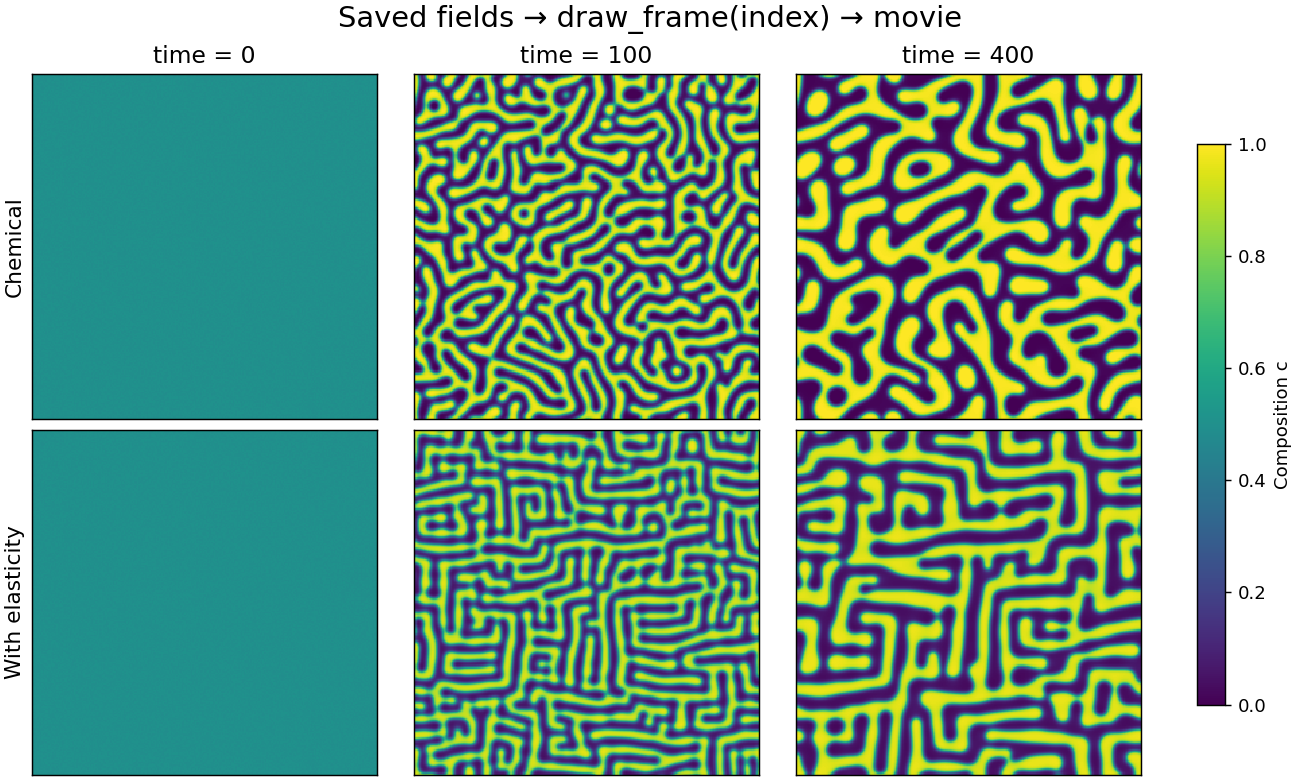

I create two images with a fixed composition scale. The function draw_frame(index) replaces their displayed values with the saved arrays at that index and updates the time label. FuncAnimation calls this function once for each saved frame. The 125 millisecond interval gives eight frames per second. This controls playback speed, not the numerical time step. I retain the movie variable so the animation object remains available. Closing the static figure prevents an extra still plot from appearing in the notebook.

In [6]:
from matplotlib.animation import FuncAnimation

fig, axes = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
images = []
for ax, field, title in zip(axes, [chemical_frames[0], elastic_frames[0]],
                            ["Chemical", "With elasticity"]):
    image = ax.imshow(field, origin="lower", vmin=0, vmax=1,
                      cmap="viridis", interpolation="nearest",
                      extent=(0, movie_n, 0, movie_n))
    images.append(image)
    ax.set_title(title)
    ax.set_xlabel("y (dimensionless)")
    ax.set_ylabel("x (dimensionless)")
fig.colorbar(images[0], ax=axes, label="Composition c (dimensionless)", shrink=0.8)
time_label = fig.suptitle(f"Seed {seed} | time = 0")

def draw_frame(index):
    images[0].set_data(chemical_frames[index])
    images[1].set_data(elastic_frames[index])
    time_label.set_text(f"Seed {seed} | time = {times[index]:g}")
    return images[0], images[1], time_label

movie = FuncAnimation(fig, draw_frame, frames=len(times),
                      interval=125, repeat=True)
plt.close(fig)

## Step 7: Save and display the movie

I use Matplotlib’s FFMpegWriter to encode the frames as an MP4. This requires the separate FFmpeg program on the system PATH, in addition to NumPy, Matplotlib and IPython. If it is missing in a Colab/Linux environment, I can install it in a separate cell with `!apt-get -qq install ffmpeg`; on macOS with Homebrew, the terminal command is `brew install ffmpeg`. IPython’s Video displays the saved file inside Jupyter or Colab. Setting embed=True stores the movie in the notebook output, so the notebook can carry the result with it. The controls allow playback and pause; loop repeats playback, not the physical evolution.

In [7]:
from matplotlib.animation import FFMpegWriter
from IPython.display import Video, display

movie_path = "phase-field-comparison.mp4"
movie.save(movie_path, writer=FFMpegWriter(fps=8), dpi=120)
print("Saved movie:", movie_path)
display(Video(movie_path, embed=True,
              html_attributes="controls loop muted playsinline"))

Saved movie: phase-field-comparison.mp4


## Explore the result

The larger calculation uses the same evolution law as the short check. The movie shows later stages, not a proof of equilibrium or numerical convergence. The initial random perturbation is still added only once.

For a JavaScript animation inside the notebook, an alternative to the MP4 display is 

```python
from IPython.display import HTML, display
with plt.rc_context({"animation.embed_limit": 50}):
    display(HTML(movie.to_jshtml()))
```

I allow up to 50 MiB of embedded frames in this alternative.. This stores individual rendered frames and can make the notebook substantially larger.

Further reading: [Matplotlib animation](https://matplotlib.org/stable/users/explain/animations/animations.html) and [IPython Video display](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html#IPython.display.Video).